# Quick EDA - Loan Default Prediction Dataset

Dataset: Kaggle "Loan Default Prediction Dataset" (nikhil1e9)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## Exploratory data analysis

In [2]:
# Basic overview
DATA_PATH = "Loan_default.csv" 
df = pd.read_csv(DATA_PATH)

TARGET = "Default"  

df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
# Basic Overview
print(f"Shape: {df.shape}")
print("\nColumn Info:")
df.info()

Shape: (255347, 18)

Column Info:
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  

In [4]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [5]:
# Data Quality Check — Missing Values & Duplicates
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
print(missing_df[missing_df["missing_count"] > 0])

dupes = df.duplicated().sum()
print(f"\nDuplicate rows: {dupes}")

Empty DataFrame
Columns: [missing_count, missing_pct]
Index: []

Duplicate rows: 0


In [6]:
# Quick sanity checks on obviously-problematic values
if "Income" in df.columns:
    print(f"Rows with Income <= 0: {(df['Income'] <= 0).sum()}")
if "LoanAmount" in df.columns:
    print(f"Rows with LoanAmount <= 0: {(df['LoanAmount'] <= 0).sum()}")
if "Age" in df.columns:
    print(f"Age range: {df['Age'].min()} - {df['Age'].max()}")

Rows with Income <= 0: 0
Rows with LoanAmount <= 0: 0
Age range: 18 - 69


In [7]:
# Target Variable Distribution
target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True) * 100
print(target_counts)
print(f"\nDefault rate: {target_pct[1]:.2f}%")

Default
0    225694
1     29653
Name: count, dtype: int64

Default rate: 11.61%


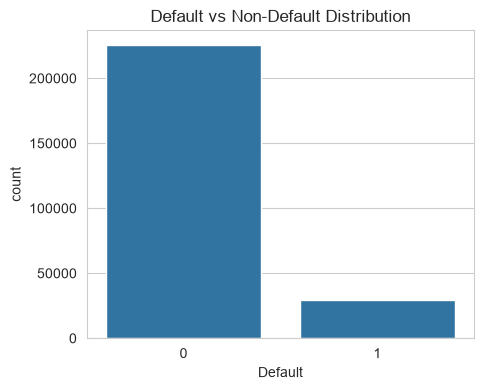

In [8]:
plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df)
plt.title("Default vs Non-Default Distribution")
plt.show()

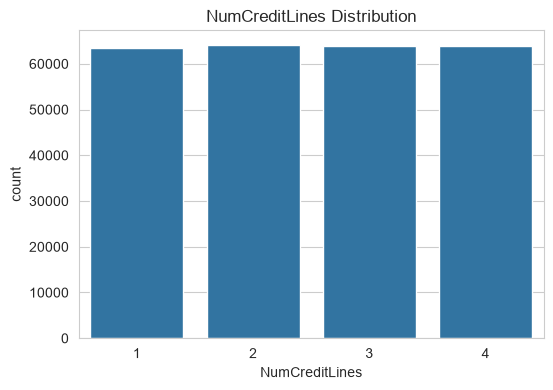

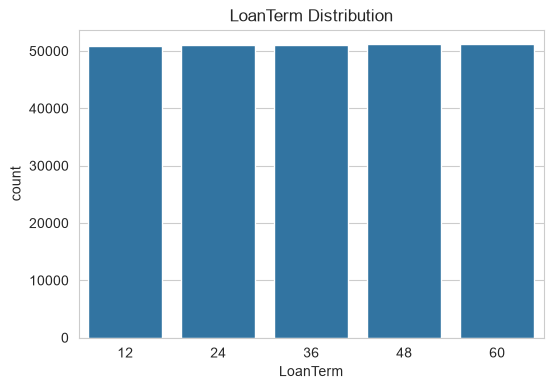

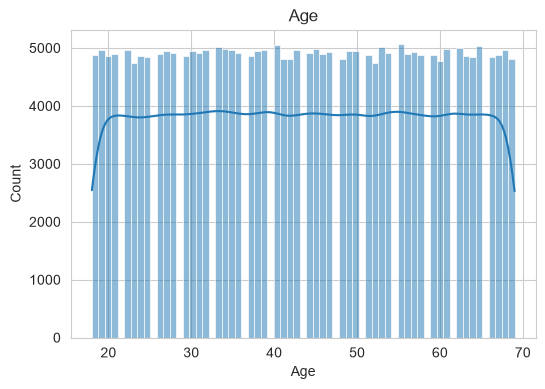

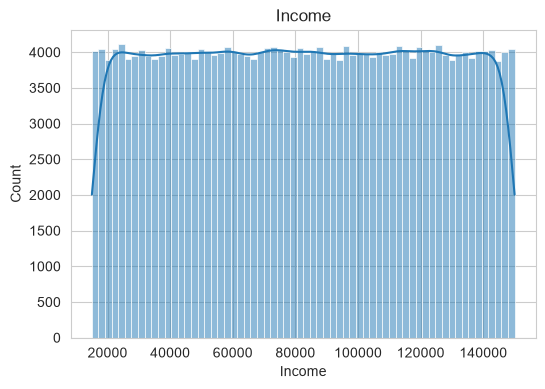

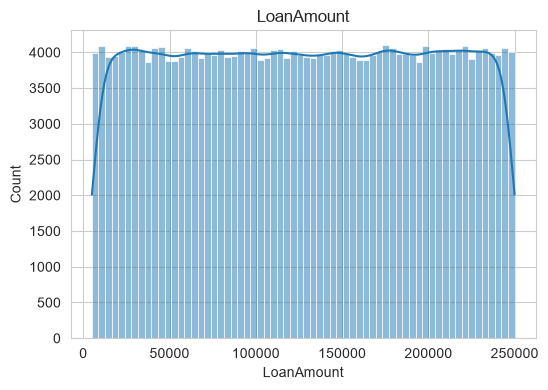

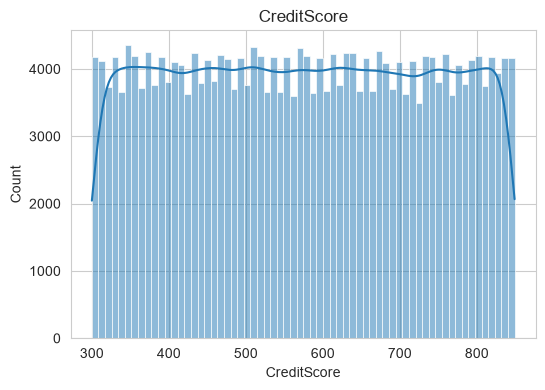

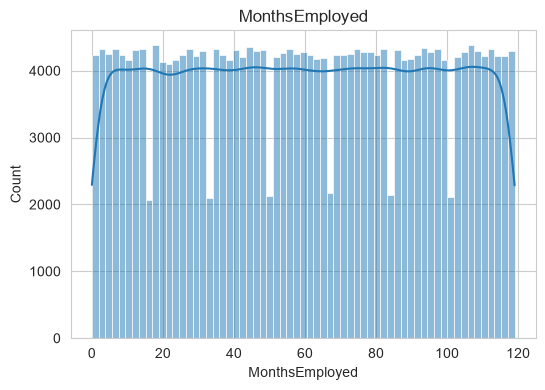

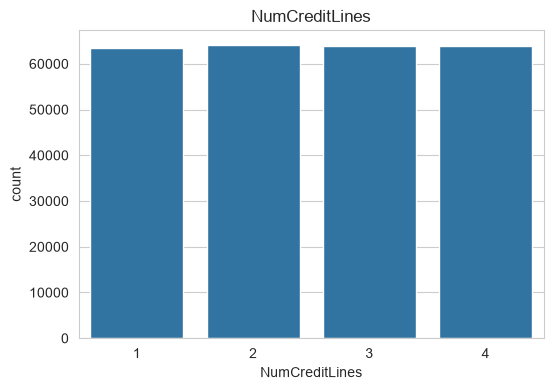

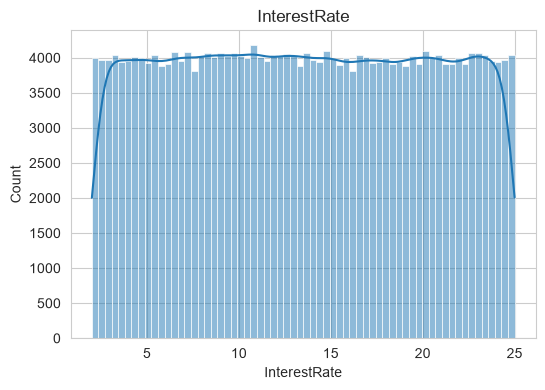

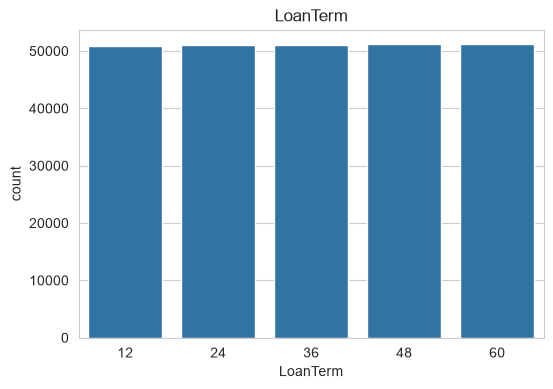

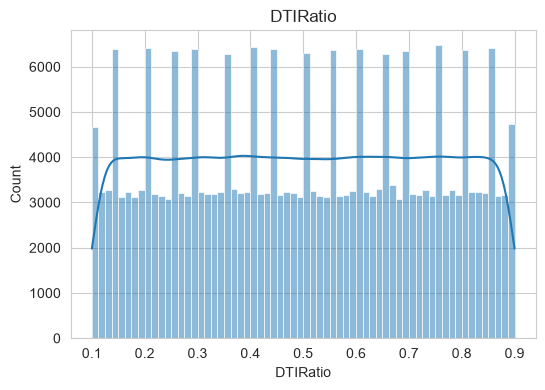

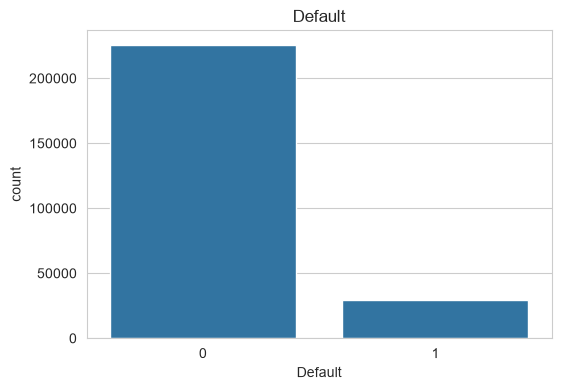

In [9]:
# Univariate Analysis — Numeric Columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(6, 4))
sns.countplot(x="NumCreditLines", data=df)
plt.title("NumCreditLines Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x="LoanTerm", data=df)
plt.title("LoanTerm Distribution")
plt.show()
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    if df[col].nunique() <= 10:   # discrete/categorical-like numeric columns
        sns.countplot(x=col, data=df)
    else:
        sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()

In [10]:
# Univariate Analysis — Categorical Columns
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
categorical_cols.remove("LoanID")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


Education:
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType:
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage:
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents:
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose:
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner:
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


C:\Users\Ayush\AppData\Local\Temp\ipykernel_13248\2564707540.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()


In [11]:
# Bivariate Analysis — Categorical Features vs Default
for col in categorical_cols:
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    print(f"\nDefault rate by {col} (%):")
    print(rate)


Default rate by Education (%):
Education
High School    12.878895
Bachelor's     12.101109
Master's       10.871721
PhD            10.585958
Name: Default, dtype: float64

Default rate by EmploymentType (%):
EmploymentType
Unemployed       13.552895
Part-time        11.965213
Self-employed    11.462029
Full-time         9.463366
Name: Default, dtype: float64

Default rate by MaritalStatus (%):
MaritalStatus
Divorced    12.532781
Single      11.912436
Married     10.397177
Name: Default, dtype: float64

Default rate by HasMortgage (%):
HasMortgage
No     12.345108
Yes    10.880581
Name: Default, dtype: float64

Default rate by HasDependents (%):
HasDependents
No     12.724423
Yes    10.502419
Name: Default, dtype: float64

Default rate by LoanPurpose (%):
LoanPurpose
Business     12.326017
Auto         11.881441
Education    11.838055
Other        11.788506
Home         10.234762
Name: Default, dtype: float64

Default rate by HasCoSigner (%):
HasCoSigner
No     12.866051
Yes    10.3601

In [12]:
# Bivariate Analysis — Numeric Features vs Default
print("Mean values by Default status:")
df.groupby(TARGET)[numeric_cols].mean().T

Mean values by Default status:


Default,0,1
Age,44.409962,36.559539
Income,83899.165995,71844.722659
LoanAmount,125353.656017,144515.311469
CreditScore,576.232270,559.286143
MonthsEmployed,60.764721,50.235457
NumCreditLines,2.489566,2.588338
InterestRate,13.176994,15.896227
LoanTerm,36.022544,36.051394
DTIRatio,0.498602,0.512467
Default,0.000000,1.000000


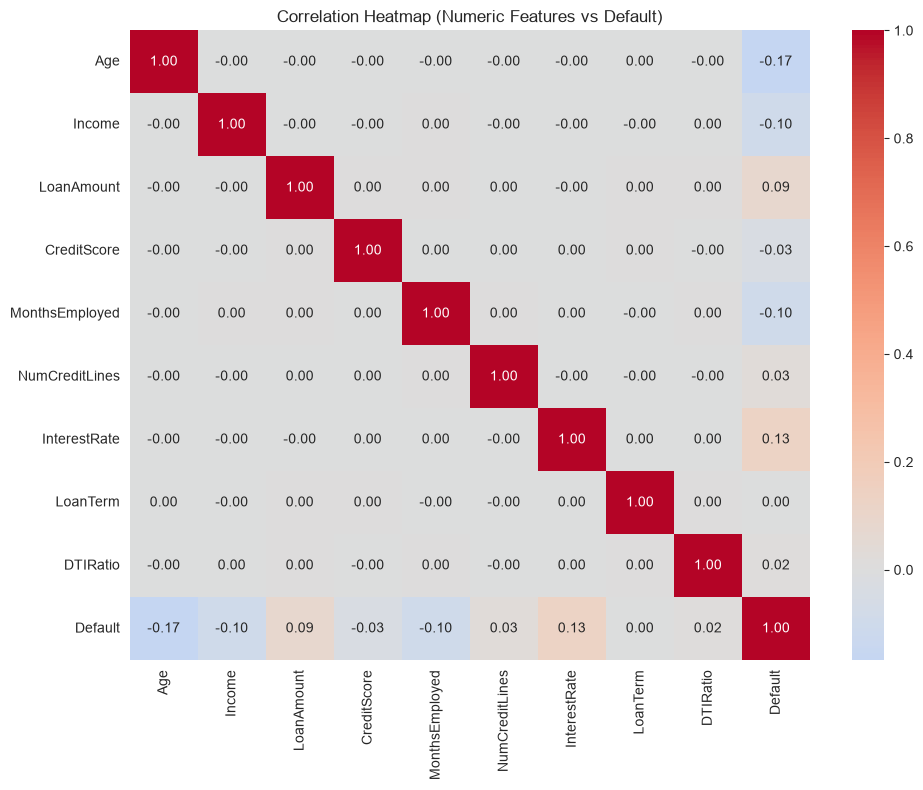

In [13]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numeric Features vs Default)")
plt.tight_layout()
plt.show()

In [14]:
# Top Correlated Features with Default
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
target_corr

Age              -0.167783
InterestRate      0.131273
Income           -0.099119
MonthsEmployed   -0.097374
LoanAmount        0.086659
CreditScore      -0.034166
NumCreditLines    0.028330
DTIRatio          0.019236
LoanTerm          0.000545
Name: Default, dtype: float64

## Observations

Average age : 43
Average income : 82500(Approx)
Average loan amount : 127579(Approx)
Average interest rate : 13.5(Approx)
Average loan term : 36 months

Default rate : 11.61%

No duplicate rows and missing values found.

People from an early age(18-25) and people from the later age(65-70) have less borrowings of the loan than people in the middle.

And a very weird thing came to know that people with less income have less borrowings of loans and that's ok but people with high income also have less borrowings of loans.

People who borrow loans for business have the highest default rate and people who borrow loans for home have the least default rate.

'Younger age + low income + high loan amount + high interest rate' this combination can be the highest risk of default.

Default rate of different employment type:
Unemployed       13.552895
Part-time        11.965213
Self-employed    11.462029
Full-time         9.463366
Default rate by marital status:
Divorced    12.532781
Single      11.912436
Married     10.397177

Default rate by mortgage
People who have no mortgage     12.345108
People who have mortgage   10.880581
Also we can see that we have every type of customers and in almost equal distribution.
The correlation heatmap shows that the features are largely independent of each other (near-zero inter-feature correlation).
From this correlation heatmap, we can observe that individual features also have only a weak-to-moderate correlation with Default (max |0.17|)
So all of these, suggests that the dataset is synthetically/randomly generated — real-world credit risk data typically shows stronger interdependencies between features and at least one or two strong predictors (such as Credit Score).

##  Feature Engineering

In [15]:
df['LoanToIncomeRatio'] = df['LoanAmount'] / df['Income']

df['MonthlyEMI_est'] = (df['LoanAmount'] * (df['InterestRate']/1200)) / \
                        (1 - (1 + df['InterestRate']/1200) ** (-df['LoanTerm']))
df['EMItoIncomeRatio'] = df['MonthlyEMI_est'] / (df['Income'] / 12)

In [16]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default',
       'LoanToIncomeRatio', 'MonthlyEMI_est', 'EMItoIncomeRatio'],
      dtype='str')

In [17]:
from sklearn.preprocessing import MinMaxScaler

# Normalize components (0-1 scale) before combining
scaler = MinMaxScaler()
df['DTIRatio_norm'] = scaler.fit_transform(df[['DTIRatio']])
df['EMItoIncomeRatio_norm'] = scaler.fit_transform(df[['EMItoIncomeRatio']])
df['LoanToIncomeRatio_norm'] = scaler.fit_transform(df[['LoanToIncomeRatio']])

# Inverting credit score — Less credit score more risk
df['CreditRisk_norm'] = 1 - scaler.fit_transform(df[['CreditScore']])

# Composite Risk Index — weighted combination
df['RiskIndex'] = (
    0.30 * df['DTIRatio_norm'] +
    0.25 * df['EMItoIncomeRatio_norm'] +
    0.25 * df['CreditRisk_norm'] +
    0.20 * df['LoanToIncomeRatio_norm']
)

In [18]:
df[['DTIRatio', 'EMItoIncomeRatio', 'CreditScore', 'LoanToIncomeRatio', 'RiskIndex']].describe()

df[['RiskIndex', 'Default']].corr()

# NaN ya infinite values check
df.isnull().sum()
df[df['EMItoIncomeRatio'] == float('inf')]

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,LoanToIncomeRatio,MonthlyEMI_est,EMItoIncomeRatio,DTIRatio_norm,EMItoIncomeRatio_norm,LoanToIncomeRatio_norm,CreditRisk_norm,RiskIndex


In [19]:
print("--- Describe ---")
print(df[['DTIRatio', 'EMItoIncomeRatio', 'CreditScore', 'LoanToIncomeRatio', 'RiskIndex']].describe())

--- Describe ---
            DTIRatio  EMItoIncomeRatio    CreditScore  LoanToIncomeRatio  \
count  255347.000000     255347.000000  255347.000000      255347.000000   
mean        0.500212          1.157286     574.264346           2.177480   
std         0.230917          1.466405     158.903867           2.178357   
min         0.100000          0.008192     300.000000           0.033749   
25%         0.300000          0.336087     437.000000           0.803628   
50%         0.500000          0.682542     574.000000           1.546720   
75%         0.700000          1.397868     712.000000           2.671744   
max         0.900000         18.086068     849.000000          16.532460   

           RiskIndex  
count  255347.000000  
mean        0.317064  
std         0.121250  
min         0.004067  
25%         0.230523  
50%         0.315214  
75%         0.402139  
max         0.900667  


In [20]:
print("\n--- Correlation with Default ---")
print(df[['RiskIndex', 'Default']].corr())


--- Correlation with Default ---
           RiskIndex   Default
RiskIndex   1.000000  0.098502
Default     0.098502  1.000000


In [21]:
print("\n--- Null values ---")
print(df.isnull().sum())


--- Null values ---
LoanID                    0
Age                       0
Income                    0
LoanAmount                0
CreditScore               0
MonthsEmployed            0
NumCreditLines            0
InterestRate              0
LoanTerm                  0
DTIRatio                  0
Education                 0
EmploymentType            0
MaritalStatus             0
HasMortgage               0
HasDependents             0
LoanPurpose               0
HasCoSigner               0
Default                   0
LoanToIncomeRatio         0
MonthlyEMI_est            0
EMItoIncomeRatio          0
DTIRatio_norm             0
EMItoIncomeRatio_norm     0
LoanToIncomeRatio_norm    0
CreditRisk_norm           0
RiskIndex                 0
dtype: int64


In [22]:
print("\n--- Infinite values in EMItoIncomeRatio ---")
print(df[df['EMItoIncomeRatio'] == float('inf')])


--- Infinite values in EMItoIncomeRatio ---
Empty DataFrame
Columns: [LoanID, Age, Income, LoanAmount, CreditScore, MonthsEmployed, NumCreditLines, InterestRate, LoanTerm, DTIRatio, Education, EmploymentType, MaritalStatus, HasMortgage, HasDependents, LoanPurpose, HasCoSigner, Default, LoanToIncomeRatio, MonthlyEMI_est, EMItoIncomeRatio, DTIRatio_norm, EMItoIncomeRatio_norm, LoanToIncomeRatio_norm, CreditRisk_norm, RiskIndex]
Index: []


In [23]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default,LoanToIncomeRatio,MonthlyEMI_est,EMItoIncomeRatio,DTIRatio_norm,EMItoIncomeRatio_norm,LoanToIncomeRatio_norm,CreditRisk_norm,RiskIndex
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,2.553470e+05,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128,2.177480,5649.062363,1.157286,0.500265,0.063564,0.129933,5.004292e-01,0.317064
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379,2.178357,4731.401956,1.466405,0.288646,0.081116,0.132032,2.894424e-01,0.121250
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000,0.033749,90.802843,0.008192,0.000000,0.000000,0.000000,1.110223e-16,0.004067
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000,0.803628,2317.463583,0.336087,0.250000,0.018138,0.046663,2.495446e-01,0.230523
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000,1.546720,4442.059863,0.682542,0.500000,0.037302,0.091702,5.009107e-01,0.315214
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000,2.671744,7259.845864,1.397868,0.750000,0.076872,0.159891,7.504554e-01,0.402139
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000,16.532460,23735.666660,18.086068,1.000000,1.000000,1.000000,1.000000e+00,0.900667


In [24]:
components = ['DTIRatio_norm', 'EMItoIncomeRatio_norm', 'CreditRisk_norm', 'LoanToIncomeRatio_norm']
correlations = df[components + ['Default']].corr()['Default'].drop('Default')
print(correlations)

weights = correlations / correlations.sum()
print(weights)

df['RiskIndex_v2'] = sum(df[col] * weights[col] for col in components)
print(df[['RiskIndex_v2', 'Default']].corr())

DTIRatio_norm             0.019236
EMItoIncomeRatio_norm     0.151861
CreditRisk_norm           0.034166
LoanToIncomeRatio_norm    0.178963
Name: Default, dtype: float64
DTIRatio_norm             0.050064
EMItoIncomeRatio_norm     0.395238
CreditRisk_norm           0.088923
LoanToIncomeRatio_norm    0.465775
Name: Default, dtype: float64
              RiskIndex_v2   Default
RiskIndex_v2      1.000000  0.181596
Default           0.181596  1.000000


## Risk Index — Iteration Notes

**v1 (manual weights):** Correlation with Default = 0.0985
Weights assigned based on domain intuition (DTI as primary factor).

**v2 (correlation-derived weights):** Correlation with Default = 0.1816
Weights recalculated based on each component's individual correlation with target,
making the formula more data-driven rather than purely assumption-based.

**Observation:** Individual features show weak linear correlation with Default 
(~0.02-0.18 range), which is expected for this dataset. This suggests the 
relationship between these features and default risk is likely non-linear —
motivating the use of a Decision Tree model (Step 6) alongside Logistic Regression,
which can capture non-linear interactions and feature combinations that a 
linear composite score cannot.

RiskIndex_v2 (correlation-derived weights) shows correlation of 0.18 with Default —
nearly double the manual-weight version (0.10), and comparable to or better than 
individual raw features. This confirms that no single linear feature strongly 
predicts default in this dataset, reinforcing the need for a proper ML model 
(non-linear/multi-feature) in the next steps rather than relying on a rule-based score alone.

## Risk Factor Identification

Default rate by Income Segment (%):
 IncomeSegment
Low Income             17.380203
Lower-Middle Income    10.537776
Upper-Middle Income     9.512994
High Income             9.020271
Name: Default, dtype: float64


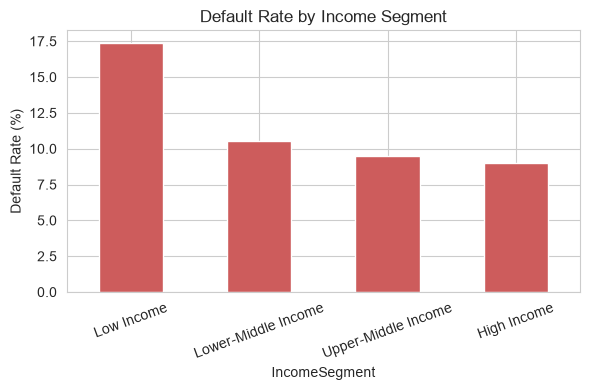


Default rate by CIBIL Band (%):
 CIBILBand
Poor (<650)       12.277748
Fair (650-749)    10.809225
Good (750+)       10.082879
Name: Default, dtype: float64


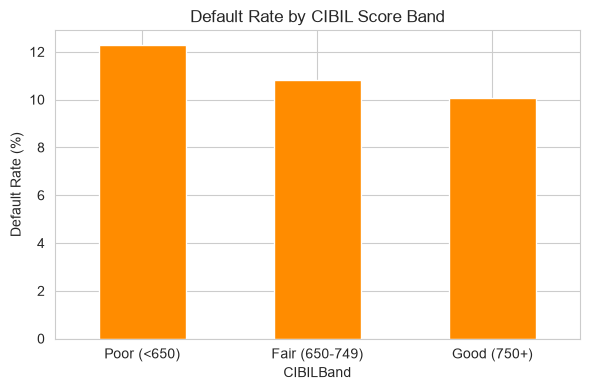

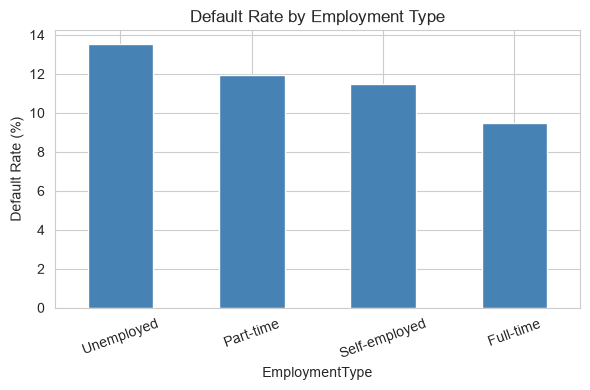


Default rate by DTI Bucket (%):
 DTIBucket
High DTI        12.306730
Mid-High DTI    11.987896
Mid-Low DTI     11.535095
Low DTI         10.659331
Name: Default, dtype: float64


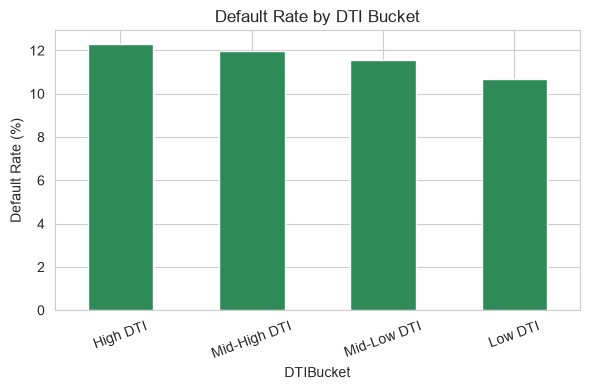


Default rate by RiskIndex_v2 Band (%):
 RiskIndexBand
High Risk           18.833905
Medium-High Risk    10.942102
Medium-Low Risk      9.303382
Low Risk             7.371900
Name: Default, dtype: float64


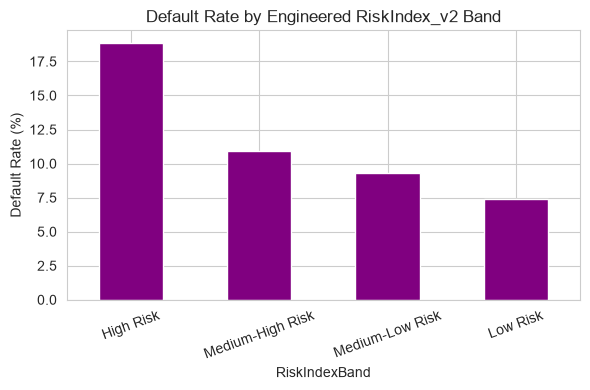

In [25]:
# 1. Income Segment
df['IncomeSegment'] = pd.qcut(
    df['Income'], q=4,
    labels=['Low Income', 'Lower-Middle Income', 'Upper-Middle Income', 'High Income']
)

income_risk = df.groupby('IncomeSegment')[TARGET].mean().sort_values(ascending=False) * 100
print("Default rate by Income Segment (%):\n", income_risk)

plt.figure(figsize=(6, 4))
income_risk.plot(kind='bar', color='indianred')
plt.title("Default Rate by Income Segment")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 2. Credit Score
df['CIBILBand'] = pd.cut(
    df['CreditScore'],
    bins=[0, 649, 749, 900],
    labels=['Poor (<650)', 'Fair (650-749)', 'Good (750+)']
)

cibil_risk = df.groupby('CIBILBand')[TARGET].mean().sort_values(ascending=False) * 100
print("\nDefault rate by CIBIL Band (%):\n", cibil_risk)

plt.figure(figsize=(6, 4))
cibil_risk.plot(kind='bar', color='darkorange')
plt.title("Default Rate by CIBIL Score Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Employment Type
emp_risk = df.groupby('EmploymentType')[TARGET].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(6, 4))
emp_risk.plot(kind='bar', color='steelblue')
plt.title("Default Rate by Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 4. DTI Ratio Bucket
df['DTIBucket'] = pd.qcut(df['DTIRatio'], q=4, labels=['Low DTI', 'Mid-Low DTI', 'Mid-High DTI', 'High DTI'])

dti_risk = df.groupby('DTIBucket')[TARGET].mean().sort_values(ascending=False) * 100
print("\nDefault rate by DTI Bucket (%):\n", dti_risk)

plt.figure(figsize=(6, 4))
dti_risk.plot(kind='bar', color='seagreen')
plt.title("Default Rate by DTI Bucket")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 5. RiskIndex_v2 Band (engineered feature from feature engineering)
df['RiskIndexBand'] = pd.qcut(df['RiskIndex_v2'], q=4, labels=['Low Risk', 'Medium-Low Risk', 'Medium-High Risk', 'High Risk'])

riskindex_risk = df.groupby('RiskIndexBand')[TARGET].mean().sort_values(ascending=False) * 100
print("\nDefault rate by RiskIndex_v2 Band (%):\n", riskindex_risk)

plt.figure(figsize=(6, 4))
riskindex_risk.plot(kind='bar', color='purple')
plt.title("Default Rate by Engineered RiskIndex_v2 Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [26]:
numeric_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 
                 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']
print(df[numeric_cols + ['Default']].corr()['Default'].sort_values(ascending=False))

Default           1.000000
InterestRate      0.131273
LoanAmount        0.086659
NumCreditLines    0.028330
DTIRatio          0.019236
LoanTerm          0.000545
CreditScore      -0.034166
MonthsEmployed   -0.097374
Income           -0.099119
Age              -0.167783
Name: Default, dtype: float64


Individual raw features show correlation magnitudes of 0.02-0.17 with Default 
(Age: -0.168, InterestRate: 0.131, Income: -0.099). Notably, negative correlations 
(Age, Income) are directionally expected — older, higher-income borrowers default less.

RiskIndex_v2 (0.18 correlation) outperforms every individual raw feature, 
validating the composite feature engineering approach even before modeling.

## Observations

- Income Segment shows the strongest individual-factor separation: Low Income borrowers default at 
  17.38% vs 9.02% for High Income — nearly 2x, and directionally consistent with Age/Income's negative 
  correlation with Default seen earlier.
- CIBIL Band shows a milder but expected gradient: Poor (<650) borrowers default at 12.28% vs 10.08% 
  for Good (750+) — surprising that this gap isn't larger, reinforcing the earlier finding that 
  CreditScore has only weak correlation (-0.034) with Default in this dataset.
- Employment Type confirms Step 2's finding: Unemployed (13.55%) vs Full-time (9.46%), a ~4 point gap.
- DTI Bucket shows the weakest separation (1.65 points) among individual factors — consistent with 
  DTIRatio's near-zero correlation (0.019) with Default.
- **RiskIndex_v2 Band shows the largest separation of any factor tested — 11.46 percentage points 
  (7.37% Low Risk → 18.83% High Risk)** — wider than even Income Segment alone. This directly validates 
  Step 3's finding that the correlation-weighted composite (0.182) outperforms every individual raw 
  feature, and confirms RiskIndex_v2 as the strongest single risk signal identified in this analysis.

## Borrower Segmentation
Borrowers are segmented using percentile cutoffs on RiskIndex_v2 (bottom 40% / next 40% / top 20%).

Note: Band names are *inspired by* the RBI asset classification (Standard / Sub-standard / Doubtful).
In actual RBI norms, classification depends on days past due (e.g., 90+ days = NPA) on an existing loan.
Here, the same vocabulary is used for *pre-disbursal* risk bands based on RiskIndex_v2 percentiles,
purely for Indian lending context.

In [27]:
print(df['RiskIndex_v2'].describe())
print(df['RiskIndex_v2'].quantile([0.2, 0.4, 0.5, 0.6, 0.8, 0.9]))

count    255347.000000
mean          0.155187
std           0.093790
min           0.002015
25%           0.097042
50%           0.133285
75%           0.182924
max           0.947139
Name: RiskIndex_v2, dtype: float64
0.2    0.089031
0.4    0.118807
0.5    0.133285
0.6    0.149544
0.8    0.200317
0.9    0.264949
Name: RiskIndex_v2, dtype: float64


In [28]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and not name.startswith('_'):
        risk_cols = [c for c in obj.columns if 'risk' in str(c).lower()]
        print(name, obj.shape, risk_cols)

df (255347, 31) ['CreditRisk_norm', 'RiskIndex', 'RiskIndex_v2', 'RiskIndexBand']
missing_df (18, 2) []
corr (10, 10) []


In [29]:
low_cut = df['RiskIndex_v2'].quantile(0.40)
high_cut = df['RiskIndex_v2'].quantile(0.80)

def assign_segment(x):
    if x <= low_cut:
        return 'Low Risk'
    elif x <= high_cut:
        return 'Medium Risk'
    return 'High Risk'

df['RiskSegment'] = df['RiskIndex_v2'].apply(assign_segment)
df['RiskSegment'] = pd.Categorical(df['RiskSegment'],
                                   categories=['Low Risk', 'Medium Risk', 'High Risk'],
                                   ordered=True)

In [30]:
rbi_map = {
    'Low Risk': 'Standard',
    'Medium Risk': 'Sub-standard (Watchlist)',
    'High Risk': 'Doubtful'
}
df['RBI_Style_Band'] = df['RiskSegment'].map(rbi_map)
df['RBI_Style_Band'] = pd.Categorical(
    df['RBI_Style_Band'],
    categories=['Standard', 'Sub-standard (Watchlist)', 'Doubtful'],
    ordered=True
)

In [31]:
overall_rate = df['Default'].mean()
total_defaults = df['Default'].sum()

seg = df.groupby('RBI_Style_Band', observed=True).agg(
    Borrowers=('Default', 'size'),
    Defaults=('Default', 'sum'),
    DefaultRate=('Default', 'mean')
)
seg['PortfolioShare_%'] = (seg['Borrowers'] / len(df) * 100).round(1)
seg['DefaultsCaptured_%'] = (seg['Defaults'] / total_defaults * 100).round(1)
seg['DefaultRate_%'] = (seg['DefaultRate'] * 100).round(2)
seg['Lift'] = (seg['DefaultRate'] / overall_rate).round(2)

print(seg[['Borrowers', 'PortfolioShare_%', 'DefaultRate_%', 'DefaultsCaptured_%', 'Lift']])

                          Borrowers  PortfolioShare_%  DefaultRate_%  \
RBI_Style_Band                                                         
Standard                     102139              40.0           8.03   
Sub-standard (Watchlist)     102138              40.0          10.80   
Doubtful                      51070              20.0          20.41   

                          DefaultsCaptured_%  Lift  
RBI_Style_Band                                      
Standard                                27.6  0.69  
Sub-standard (Watchlist)                37.2  0.93  
Doubtful                                35.2  1.76  


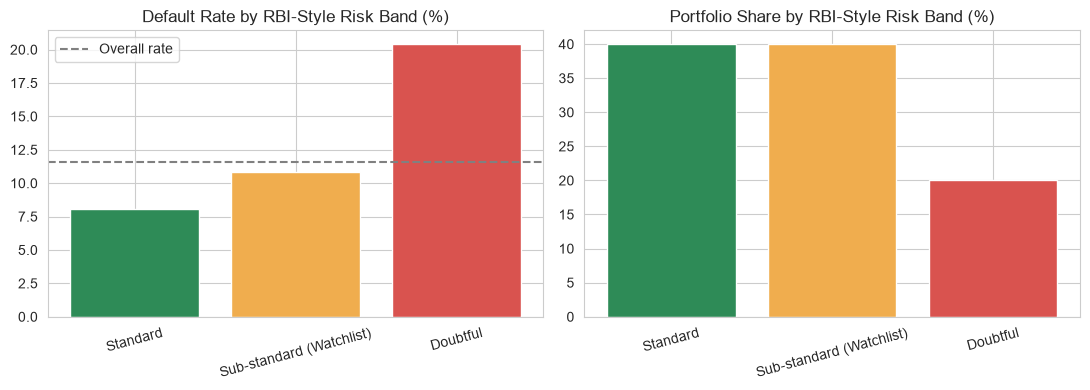

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#2e8b57', '#f0ad4e', '#d9534f']

ax[0].bar(seg.index.astype(str), seg['DefaultRate_%'], color=colors)
ax[0].axhline(overall_rate * 100, ls='--', color='gray', label='Overall rate')
ax[0].set_title('Default Rate by RBI-Style Risk Band (%)')
ax[0].legend()

ax[1].bar(seg.index.astype(str), seg['PortfolioShare_%'], color=colors)
ax[1].set_title('Portfolio Share by RBI-Style Risk Band (%)')

ax[0].tick_params(axis='x', rotation=15)
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [33]:
pd.crosstab(df['RBI_Style_Band'], df['EmploymentType'], normalize='index').round(3) * 100

EmploymentType,Full-time,Part-time,Self-employed,Unemployed
RBI_Style_Band,,,,
Standard,25.0,25.1,25.1,24.8
Sub-standard (Watchlist),24.9,25.2,25.0,25.0
Doubtful,24.9,25.2,24.7,25.3


In [34]:
df.to_csv("loan_data_segmented.csv", index=False)

# Observations

- Percentile cutoffs were used instead of fixed probability thresholds because the overall 
  default rate (~11.6%) is too low for thresholds like 30%/60% to be meaningful.
- Doubtful band (20% of borrowers) has a 20.41% default rate (lift 1.76x) and captures 35.2% 
  of all defaults. Standard band defaults at 8.03% (lift 0.69x).
- The Standard-to-Doubtful default rate spread is 12.4 percentage points, confirming 
  RiskIndex_v2 separates borrower risk meaningfully.
- Sub-standard (Watchlist) band (40% of portfolio) has a 10.80% default rate, close to the 
  overall average, which is expected for a middle bucket; it is the natural candidate for 
  manual review.
- Employment Type is evenly distributed (~25% each) across all three bands, meaning 
  RiskIndex_v2 does not capture employment. Since Unemployed borrowers still default more 
  (13.55% vs 9.46% for Full-time), employment adds independent signal for the model in Step 6.

## Creating a model

In [35]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import roc_auc_score

df = pd.read_csv("loan_data_segmented.csv")

# 1) Leakage + ID columns
leak_cols = ["RiskIndex_v2", "RiskSegment", "RBI_Style_Band"]
id_cols   = ["LoanID"]

# 2) Bucket columns of risk factor identification duplicate the raw features, so exclude them
bucket_cols = ["IncomeSegment", "CIBILBand", "DTIBucket", "RiskIndexBand"]

norm_cols = ["DTIRatio_norm", "EMItoIncomeRatio_norm", "LoanToIncomeRatio_norm",
             "CreditRisk_norm", "RiskIndex"]

drop_cols = [c for c in leak_cols + id_cols + bucket_cols + norm_cols if c in df.columns]
X = df.drop(columns=drop_cols + ["Default"]).copy()
y = df["Default"]

# 3) Education has a natural order, so ordinal-encode it
if "Education" in X.columns and not pd.api.types.is_numeric_dtype(X["Education"]):
    edu_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
    print("Education values:", X["Education"].unique())
    X["Education"] = X["Education"].map(edu_map)

# 4) One-hot encode any remaining text columns
non_numeric = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()
print("Remaining non-numeric cols:", non_numeric)
if non_numeric:
    X = pd.get_dummies(X, columns=non_numeric, drop_first=True)

X = X.astype(float)

# 5) Safety checks
print("Nulls:", X.isnull().sum().sum(), "| Education NaN:", X["Education"].isnull().sum() if "Education" in X else "n/a")
print(X.shape, "| Default rate:", round(y.mean()*100, 2), "%")

Education values: <ArrowStringArray>
['Bachelor's', 'Master's', 'High School', 'PhD']
Length: 4, dtype: str
Remaining non-numeric cols: ['EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']
Nulls: 0 | Education NaN: 0
(255347, 25) | Default rate: 11.61 %


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# Stratify so train and test keep the same default rate (imbalanced data)

In [37]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s  = scaler.transform(X_test)

# class_weight='balanced': defaults are only ~11-12%; without it the model would predict "no default" for almost everyone
logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
logreg.fit(X_train_s, y_train)

# Coefficients -> odds ratios (easy to explain to the business)
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logreg.coef_[0],
    "OddsRatio": np.exp(logreg.coef_[0])
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef.head(10))

lr_proba = logreg.predict_proba(X_test_s)[:, 1]
print("LogReg AUC:", round(roc_auc_score(y_test, lr_proba), 4))

                         Feature  Coefficient  OddsRatio
0                            Age    -0.592103   0.553163
10             LoanToIncomeRatio     0.478693   1.613964
6                   InterestRate     0.465850   1.593368
4                 MonthsEmployed    -0.341127   0.710969
15     EmploymentType_Unemployed     0.188552   1.207500
24               HasCoSigner_Yes    -0.132421   0.875972
19             HasDependents_Yes    -0.128911   0.879052
3                    CreditScore    -0.125659   0.881915
13      EmploymentType_Part-time     0.117321   1.124481
14  EmploymentType_Self-employed     0.108443   1.114542
LogReg AUC: 0.7616


Tree AUC: 0.7154


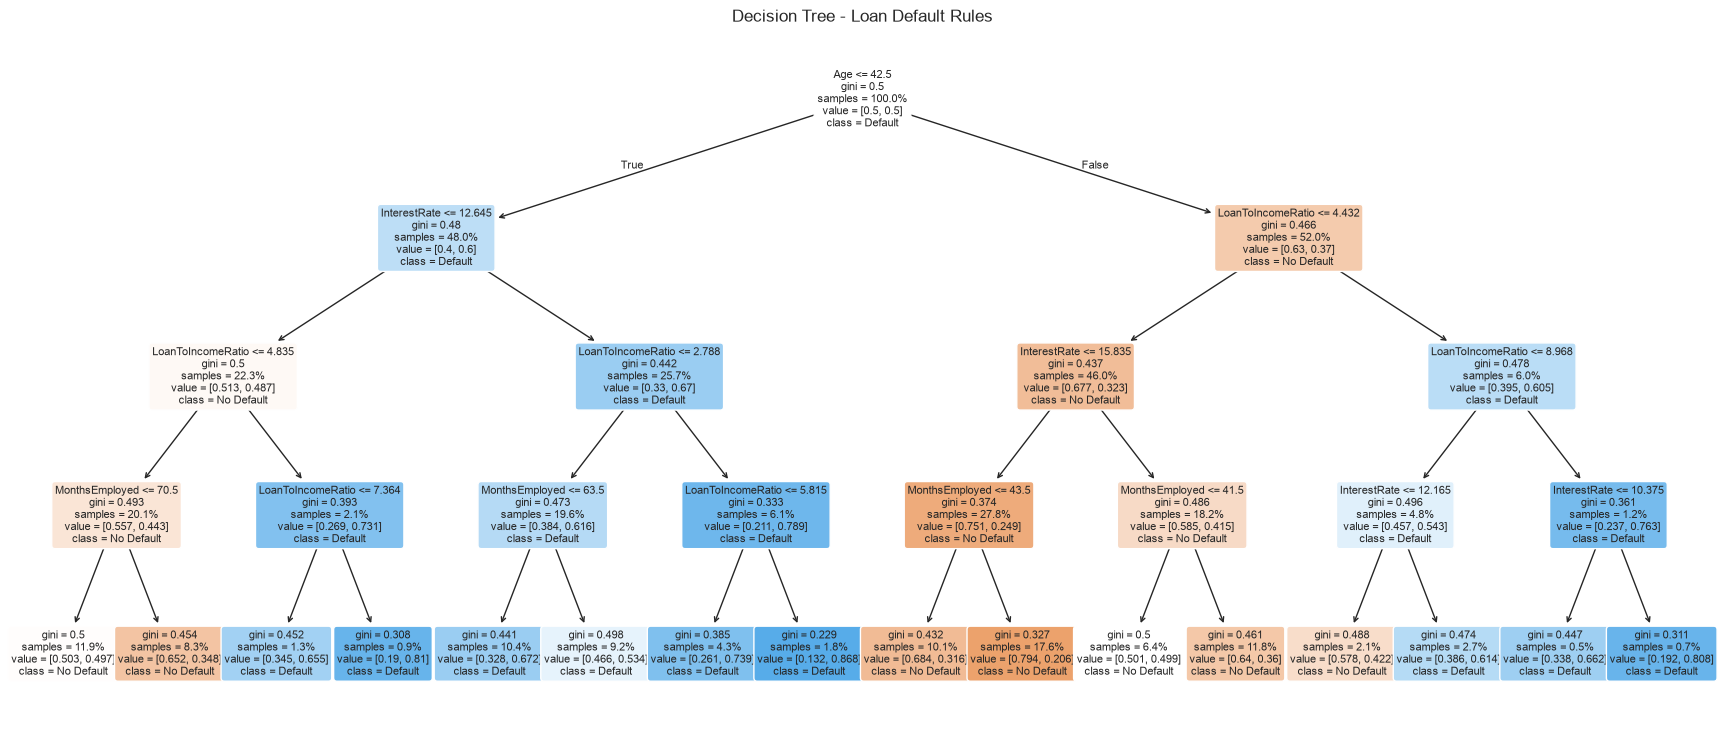

|--- Age <= 42.50
|   |--- InterestRate <= 12.64
|   |   |--- LoanToIncomeRatio <= 4.84
|   |   |   |--- MonthsEmployed <= 70.50
|   |   |   |   |--- class: 0
|   |   |   |--- MonthsEmployed >  70.50
|   |   |   |   |--- class: 0
|   |   |--- LoanToIncomeRatio >  4.84
|   |   |   |--- LoanToIncomeRatio <= 7.36
|   |   |   |   |--- class: 1
|   |   |   |--- LoanToIncomeRatio >  7.36
|   |   |   |   |--- class: 1
|   |--- InterestRate >  12.64
|   |   |--- LoanToIncomeRatio <= 2.79
|   |   |   |--- MonthsEmployed <= 63.50
|   |   |   |   |--- class: 1
|   |   |   |--- MonthsEmployed >  63.50
|   |   |   |   |--- class: 1
|   |   |--- LoanToIncomeRatio >  2.79
|   |   |   |--- LoanToIncomeRatio <= 5.82
|   |   |   |   |--- class: 1
|   |   |   |--- LoanToIncomeRatio >  5.82
|   |   |   |   |--- class: 1
|--- Age >  42.50
|   |--- LoanToIncomeRatio <= 4.43
|   |   |--- InterestRate <= 15.84
|   |   |   |--- MonthsEmployed <= 43.50
|   |   |   |   |--- class: 0
|   |   |   |--- MonthsEmploy

In [38]:
# Keep it shallow (depth 4, large leaves) so the tree stays readable and does not overfit
tree = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=500,
    class_weight="balanced", random_state=42
)
tree.fit(X_train, y_train)   # trees do not need scaling

dt_proba = tree.predict_proba(X_test)[:, 1]
print("Tree AUC:", round(roc_auc_score(y_test, dt_proba), 4))

plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=X.columns, class_names=["No Default", "Default"],
          filled=True, rounded=True, fontsize=8, proportion=True)
plt.title("Decision Tree - Loan Default Rules")
plt.show()

print(export_text(tree, feature_names=list(X.columns), max_depth=3))

In [39]:
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(8))

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "AUC": [roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, dt_proba)],
})
print(comparison)

# For evaluation + cost-based threshold tuning
results = pd.DataFrame({
    "y_true": y_test.values, "lr_proba": lr_proba, "dt_proba": dt_proba
}, index=y_test.index)
results.to_csv("test_predictions.csv")

Age                             0.375654
LoanToIncomeRatio               0.309162
InterestRate                    0.217499
MonthsEmployed                  0.097684
EmploymentType_Self-employed    0.000000
LoanPurpose_Other               0.000000
LoanPurpose_Home                0.000000
LoanPurpose_Education           0.000000
dtype: float64
                 Model       AUC
0  Logistic Regression  0.761586
1        Decision Tree  0.715416


In [40]:
test_idx = X_test.index
rix_auc = roc_auc_score(y_test, df.loc[test_idx, "RiskIndex_v2"])
print("RiskIndex_v2 AUC (benchmark):", round(rix_auc, 4))

RiskIndex_v2 AUC (benchmark): 0.6236


# Observations
- **Excluded features:** RiskIndex / RiskIndex_v2, *_norm columns and risk bands. Reason: target leakage and multicollinearity. RiskIndex_v2 is used later only as a benchmark.
- **class_weight='balanced'** was used because the default rate is only ~11.6%.
- **Logistic Regression AUC 0.7616 vs Decision Tree AUC 0.7154.** Logistic Regression is better and also more interpretable.
- **Both models share the same top drivers:** Age, LoanToIncomeRatio, InterestRate, MonthsEmployed. This is a consistent signal.
- **LR odds ratios (per 1 SD):** LoanToIncomeRatio (1.61x) and InterestRate (1.59x) raise default odds; MonthsEmployed (0.71x) and HasCoSigner (0.88x) lower them. Unemployed borrowers have 1.21x odds.
- **CreditScore effect (OR 0.88)** is weaker than the RiskIndex_v2 weighting assumed.
- **Age** as a policy rule is a fair-lending risk, so the final scorecard keeps Age as an analytical insight, not a decision rule.
- **The tree used only 4 features;** all other features have zero importance.
- **Class-weighted probabilities are not calibrated,** so Step 7 chooses the threshold by business cost, not 0.5.
- **Benchmark:** RiskIndex_v2 (rule-based) AUC = 0.6236 vs Logistic Regression 0.7616 vs Decision Tree 0.7154. The ML model improves AUC by about 0.14. The index does not include strong drivers such as Age and MonthsEmployed. RiskIndex_v2 is simple and explainable for segmentation (Step 5), but the final scorecard uses model scores.


## Evaluation

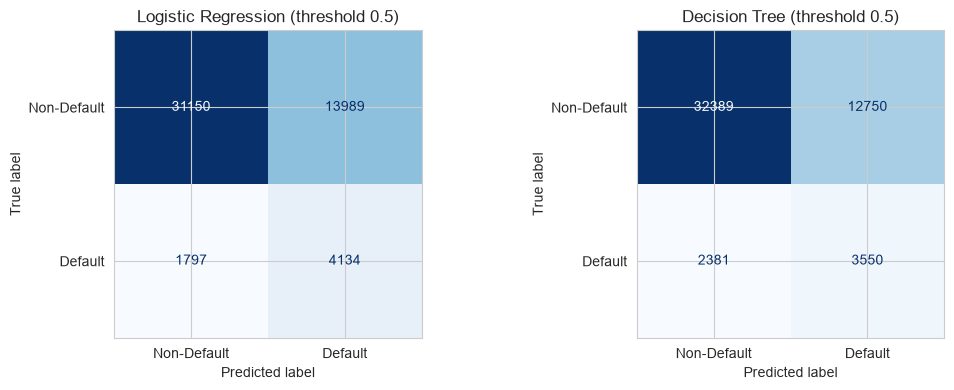

,Model,Precision,Recall,F1,AUC-ROC
0,Logistic Regression,0.2281,0.6970,0.3437,0.7616
1,Decision Tree,0.2178,0.5985,0.3194,0.7154


In [41]:
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

probas = {"Logistic Regression": lr_proba, "Decision Tree": dt_proba}

rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, p) in zip(axes, probas.items()):
    pred = (p >= 0.5).astype(int)
    rows.append({"Model": name,
                 "Precision": precision_score(y_test, pred),
                 "Recall":    recall_score(y_test, pred),
                 "F1":        f1_score(y_test, pred),
                 "AUC-ROC":   roc_auc_score(y_test, p)})
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Non-Default", "Default"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (threshold 0.5)")
plt.tight_layout(); plt.show()

pd.DataFrame(rows).round(4)

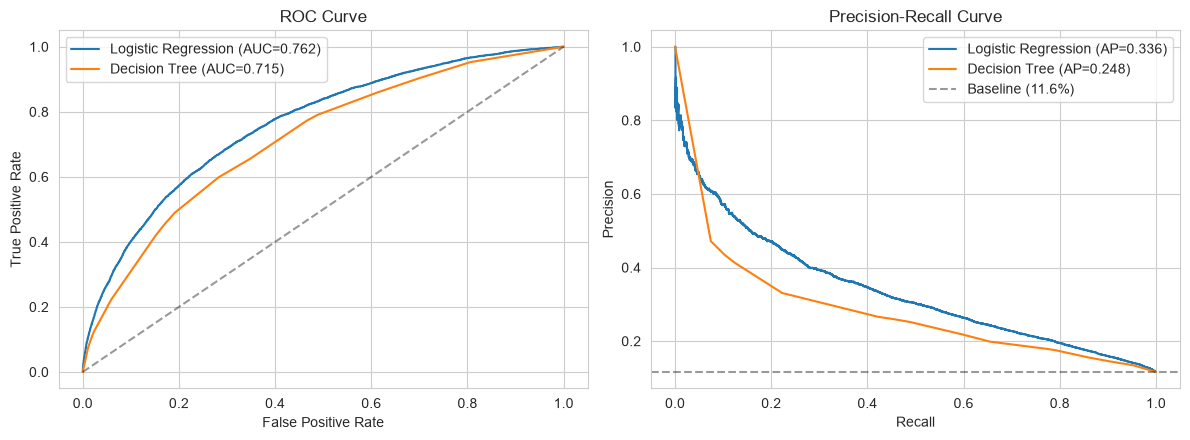

In [42]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _   = precision_recall_curve(y_test, p)
    ax1.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
    ax2.plot(rc, pr,  label=f"{name} (AP={average_precision_score(y_test,p):.3f})")

ax1.plot([0,1],[0,1],"k--",alpha=.4)
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve"); ax1.legend()
ax2.axhline(y_test.mean(), color="k", ls="--", alpha=.4, label=f"Baseline ({y_test.mean():.1%})")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve"); ax2.legend()
plt.tight_layout(); plt.show()

In [43]:
LGD = 0.60
NET_MARGIN = 0.40

cost_FN = LGD * X_test["LoanAmount"]
cost_FP = NET_MARGIN * X_test["LoanAmount"] * (X_test["InterestRate"]/100) * (X_test["LoanTerm"]/12)

print(f"Avg FN cost: {cost_FN.mean():,.0f} | Avg FP cost: {cost_FP.mean():,.0f} | FN:FP = {cost_FN.mean()/cost_FP.mean():.1f}x")

Avg FN cost: 76,679 | Avg FP cost: 20,794 | FN:FP = 3.7x


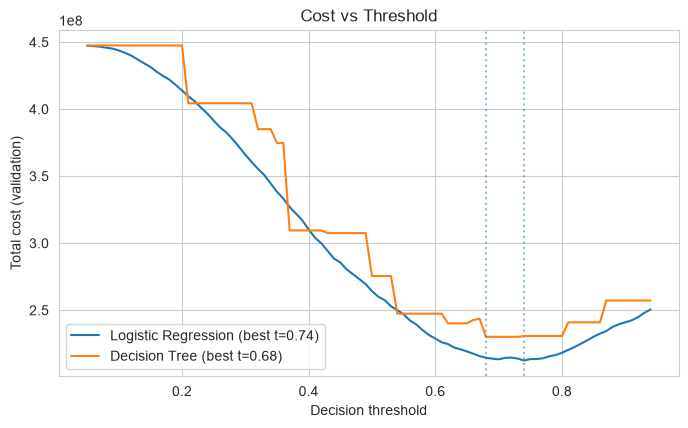

Logistic Regression: cost@0.5 = 260,499,877 | cost@0.74 = 216,253,908 | saving = 17.0% | Recall = 29.41% | Precision = 39.35%
Decision Tree: cost@0.5 = 274,411,214 | cost@0.68 = 233,608,478 | saving = 14.9% | Recall = 22.16% | Precision = 32.88%


In [44]:
from sklearn.model_selection import train_test_split

idx_val, idx_te = train_test_split(X_test.index, test_size=0.5, stratify=y_test, random_state=42)

def total_cost(idx, proba, t):
    pred = proba.loc[idx] >= t
    y = y_test.loc[idx]
    fn = ((~pred) & (y == 1)) * cost_FN.loc[idx]
    fp = (pred & (y == 0))    * cost_FP.loc[idx]
    return fn.sum() + fp.sum()

thresholds = np.arange(0.05, 0.95, 0.01)
plist = {"Logistic Regression": pd.Series(lr_proba, index=X_test.index),
         "Decision Tree":       pd.Series(dt_proba, index=X_test.index)}

fig, ax = plt.subplots(figsize=(8, 4.5))
best = {}
for name, p in plist.items():
    costs = [total_cost(idx_val, p, t) for t in thresholds]
    t_best = thresholds[int(np.argmin(costs))]
    best[name] = t_best
    ax.plot(thresholds, costs, label=f"{name} (best t={t_best:.2f})")
    ax.axvline(t_best, ls=":", alpha=.5)
ax.set(xlabel="Decision threshold", ylabel="Total cost (validation)", title="Cost vs Threshold"); ax.legend(); plt.show()

for name, p in plist.items():
    t = best[name]
    c05, copt = total_cost(idx_te, p, 0.5), total_cost(idx_te, p, t)
    pred = (p.loc[idx_te] >= t).astype(int)
    print(f"{name}: cost@0.5 = {c05:,.0f} | cost@{t:.2f} = {copt:,.0f} | saving = {(c05-copt)/c05:.1%} | "
          f"Recall = {recall_score(y_test.loc[idx_te], pred):.2%} | Precision = {precision_score(y_test.loc[idx_te], pred):.2%}")

In [45]:
# Baselines (test half)
y_te = y_test.loc[idx_te]
approve_all = (cost_FN.loc[idx_te] * (y_te == 1)).sum()
reject_all  = (cost_FP.loc[idx_te] * (y_te == 0)).sum()
p = plist["Logistic Regression"]
model_cost = total_cost(idx_te, p, best["Logistic Regression"])
print(f"Approve all: {approve_all:,.0f} | Reject all: {reject_all:,.0f} | LogReg@{best['Logistic Regression']:.2f}: {model_cost:,.0f}")
print(f"Saving vs approve-all: {(approve_all-model_cost)/approve_all:.1%}")

# LGD sensitivity
def total_cost2(idx, proba, t, cfn, cfp):
    pred = proba.loc[idx] >= t; y = y_test.loc[idx]
    return (((~pred) & (y == 1)) * cfn.loc[idx]).sum() + ((pred & (y == 0)) * cfp.loc[idx]).sum()

for lgd in [0.4, 0.6, 0.8]:
    cfn = lgd * X_test["LoanAmount"]
    cs = [total_cost2(idx_val, p, t, cfn, cost_FP) for t in thresholds]
    print(f"LGD={lgd}: best threshold = {thresholds[int(np.argmin(cs))]:.2f}")

Approve all: 258,494,024 | Reject all: 450,105,429 | LogReg@0.74: 216,253,908
Saving vs approve-all: 16.3%
LGD=0.4: best threshold = 0.80
LGD=0.6: best threshold = 0.74
LGD=0.8: best threshold = 0.67


# Observations
- **Accuracy was ignored** (default rate ~11.6%, imbalanced data). Metrics used: Precision, Recall, F1, AUC-ROC and the PR curve.
- **At threshold 0.5:** Logistic Regression has Recall 69.7% / Precision 22.8% / F1 0.344 / AUC 0.762; Decision Tree has Recall 59.9% / Precision 21.8% / F1 0.319 / AUC 0.715. Logistic Regression is better on every metric, so it is the final model.
- **class_weight='balanced'** makes the model flag many borrowers at 0.5 (high recall, low precision). The scores are ranking scores, not calibrated probabilities.
- **Cost assumptions:** LGD 60%, net margin 40% of interest income, so a missed defaulter (FN) costs ~3.7x a rejected good borrower (FP).
- **Optimal threshold (chosen on the validation half):** Logistic Regression 0.74, Decision Tree 0.68. On the test half, Logistic Regression cost is 17.0% lower than at 0.5.
- **Baselines (test half):** approve-all 258.5M, reject-all 450.1M, LR@0.74 216.3M, a 16.3% saving vs approve-all. LR@0.5 (260.5M) was slightly costlier than approve-all, so without threshold tuning the model adds no business value.
- **LGD sensitivity:** best threshold is 0.80 / 0.74 / 0.67 for LGD 0.4 / 0.6 / 0.8, so 0.74 is a stable choice.
- **Limitation:** AUC 0.76 is moderate, so the saving is 16%, not 50%. Borderline cases go to a Manual Review band (Step 8).

Holdout rows: 25535
ModelBand
Standard     16461
Watchlist     6858
High Risk     2216
Name: count, dtype: int64


,Action,Borrowers,Pct_Borrowers,Default_Rate,Pct_of_All_Defaults,Lift,Exposure
ModelBand,,,,,,,
Standard,Approve,16461,64.464,0.053,29.578,0.459,1.930243e+09
Watchlist,Manual review,6858,26.857,0.177,41.012,1.527,9.609543e+08
High Risk,Reject,2216,8.678,0.394,29.410,3.389,3.790671e+08


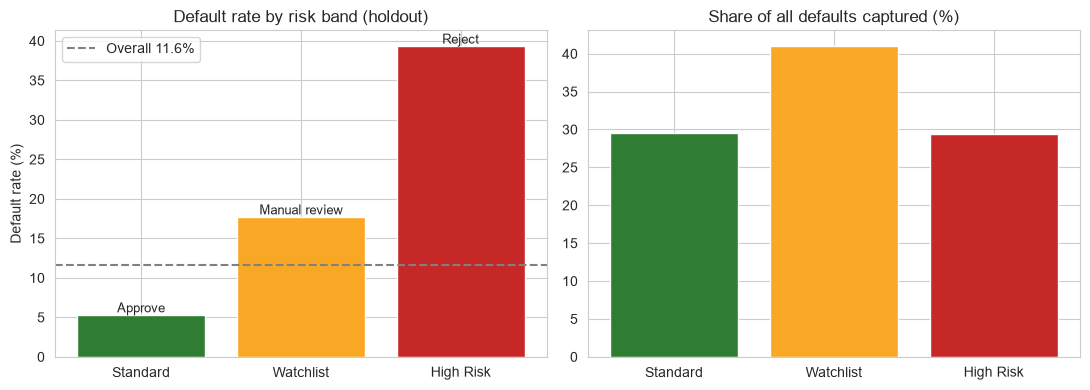

,Method,Defaults captured in top 20% (%)
0,Rule-based RiskIndex_v2 (Step 5),35.5
1,Logistic Regression score (Step 6),51.5


approve-all : 258,494,024   (Step 7: 258,494,024)
policy@0.74: 216,253,908   (Step 7: 216,253,908)

--- Headline (holdout half, illustrative INR) ---
Approve-all expected cost  : Rs 25.85 Cr
Policy (LogReg) cost       : Rs 21.63 Cr
Saving vs approve-all      : Rs 4.22 Cr (16.3%)
Loss avoided by Reject band: Rs 9.11 Cr
Margin forgone (good rejected): Rs 4.89 Cr
Loss still leaking (Approve + Manual review): Rs 16.74 Cr


,Action,Loan_Exposure,Loss_from_defaulters,Margin_from_good_borrowers
Band,,,,
Standard,Approve,Rs 193.02 Cr,Rs 6.29 Cr,Rs 25.25 Cr
Watchlist,Manual review,Rs 96.10 Cr,Rs 10.44 Cr,Rs 14.87 Cr
High Risk,Reject,Rs 37.91 Cr,Rs 9.11 Cr,Rs 4.89 Cr


,LGD,Best_threshold,Approve_all,Policy,Saving_%
0,0.4,0.80,Rs 17.23 Cr,Rs 15.59 Cr,9.5
1,0.6,0.74,Rs 25.85 Cr,Rs 21.63 Cr,16.3
2,0.8,0.67,Rs 34.47 Cr,Rs 26.24 Cr,23.9


,Feature,Coefficient,OddsRatio,Direction
0,Age,-0.592,0.553,Lowers default risk
10,LoanToIncomeRatio,0.479,1.614,Raises default risk
6,InterestRate,0.466,1.593,Raises default risk
4,MonthsEmployed,-0.341,0.711,Lowers default risk
15,EmploymentType_Unemployed,0.189,1.207,Raises default risk
24,HasCoSigner_Yes,-0.132,0.876,Lowers default risk
19,HasDependents_Yes,-0.129,0.879,Lowers default risk
3,CreditScore,-0.126,0.882,Lowers default risk


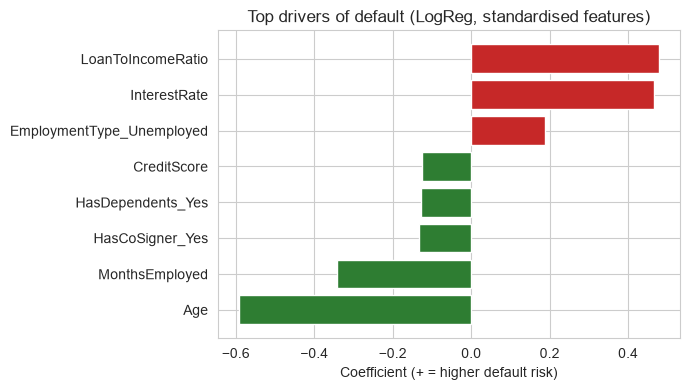

(51070, 23) | columns: ['Age', 'Income', 'LoanAmount', 'InterestRate', 'LoanTerm', 'CreditScore', 'DTIRatio', 'LoanToIncomeRatio', 'EMItoIncomeRatio', 'LoanID', 'EmploymentType', 'IncomeSegment', 'CIBILBand', 'DTIBucket', 'RiskIndex_v2', 'RBI_Style_Band', 'Default', 'RiskScore', 'Cost_FN', 'Cost_FP', 'ModelBand', 'Action', 'Eval_Half']


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

T_APPROVE = 0.50
T_REJECT = round(float(best["Logistic Regression"]), 2)     # From evaluation : 0.74
assert abs(T_REJECT - 0.74) < 1e-9, f"Expected threshold 0.74 (From evaluation): {T_REJECT}"

p_lr = plist["Logistic Regression"]                          # Series, index = X_test.index

feat_cols = ["Age", "Income", "LoanAmount", "InterestRate", "LoanTerm", "CreditScore",
             "DTIRatio", "LoanToIncomeRatio", "EMItoIncomeRatio"]
extra_cols = ["LoanID", "EmploymentType", "IncomeSegment", "CIBILBand", "DTIBucket",
              "RiskIndex_v2", "RBI_Style_Band"]
extra_cols = [c for c in extra_cols if c in df.columns]

res = X_test[feat_cols].copy().join(df.loc[X_test.index, extra_cols])
res["Default"] = y_test
res["RiskScore"] = p_lr          
res["Cost_FN"] = cost_FN
res["Cost_FP"] = cost_FP

res["ModelBand"] = pd.cut(
    res["RiskScore"],
    bins=[-np.inf, T_APPROVE, T_REJECT, np.inf],
    labels=["Standard", "Watchlist", "High Risk"],
    right=False,
)
action_map = {"Standard": "Approve", "Watchlist": "Manual review", "High Risk": "Reject"}
res["Action"] = res["ModelBand"].map(action_map).astype(str)
res["Eval_Half"] = np.where(res.index.isin(idx_te), "holdout", "validation")

ho = res.loc[idx_te]             
print("Holdout rows:", len(ho))
print(ho["ModelBand"].value_counts().sort_index())

# Scorecard table (holdout)
overall_dr = ho["Default"].mean()
total_def = ho["Default"].sum()

scorecard = (
    ho.groupby("ModelBand", observed=True)
      .agg(Borrowers=("RiskScore", "size"),
           Defaults=("Default", "sum"),
           Default_Rate=("Default", "mean"),
           Avg_Score=("RiskScore", "mean"),
           Exposure=("LoanAmount", "sum"))
)
scorecard["Pct_Borrowers"] = scorecard["Borrowers"] / len(ho) * 100
scorecard["Pct_of_All_Defaults"] = scorecard["Defaults"] / total_def * 100
scorecard["Lift"] = scorecard["Default_Rate"] / overall_dr
scorecard["Action"] = scorecard.index.map(action_map)

scorecard_view = scorecard[["Action", "Borrowers", "Pct_Borrowers", "Default_Rate",
                            "Pct_of_All_Defaults", "Lift", "Exposure"]].round(3)
display(scorecard_view)

assert scorecard["Default_Rate"].is_monotonic_increasing, "Bands are not monotonic - check thresholds"

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#2e7d32", "#f9a825", "#c62828"]
ax[0].bar(scorecard.index.astype(str), scorecard["Default_Rate"] * 100, color=colors)
ax[0].axhline(overall_dr * 100, ls="--", c="grey", label=f"Overall {overall_dr*100:.1f}%")
ax[0].set_title("Default rate by risk band (holdout)")
ax[0].set_ylabel("Default rate (%)")
ax[0].legend()
for i, (b, r) in enumerate(scorecard.iterrows()):
    ax[0].text(i, r["Default_Rate"] * 100 + 0.3, r["Action"], ha="center", fontsize=9)
ax[1].bar(scorecard.index.astype(str), scorecard["Pct_of_All_Defaults"], color=colors)
ax[1].set_title("Share of all defaults captured (%)")
plt.tight_layout()
plt.show()

def capture_top(score, frac=0.20):
    k = int(len(ho) * frac)
    idx = score.sort_values(ascending=False).index[:k]
    return ho.loc[idx, "Default"].sum() / total_def

cmp = pd.DataFrame({
    "Method": ["Rule-based RiskIndex_v2 (Step 5)", "Logistic Regression score (Step 6)"],
    "Defaults captured in top 20% (%)": [capture_top(ho["RiskIndex_v2"]) * 100,
                                         capture_top(ho["RiskScore"]) * 100],
}).round(1)
display(cmp)

# Business impact in INR (holdout)
cfn = cost_FN.loc[idx_te]
cfp = cost_FP.loc[idx_te]
y = ho["Default"]

approve_all = (cfn * (y == 1)).sum()
policy_cost = total_cost(idx_te, p_lr, T_REJECT)

print(f"approve-all : {approve_all:,.0f}   (Step 7: 258,494,024)")
print(f"policy@{T_REJECT}: {policy_cost:,.0f}   (Step 7: 216,253,908)")
assert np.isclose(approve_all, 258_494_024, rtol=1e-4), "approve-all does not match from evaluation"
assert np.isclose(policy_cost, 216_253_908, rtol=1e-4), "policy cost does not match from evaluation"

def inr(x):
    """Amounts are treated as illustrative INR. 1 Cr = 1e7."""
    return f"Rs {x/1e7:,.2f} Cr"

rows = []
for band in ["Standard", "Watchlist", "High Risk"]:
    m = ho["ModelBand"] == band
    rows.append({
        "Band": band,
        "Action": action_map[band],
        "Loan_Exposure": ho.loc[m, "LoanAmount"].sum(),
        "Loss_from_defaulters": cfn[m & (y == 1)].sum(),
        "Margin_from_good_borrowers": cfp[m & (y == 0)].sum(),
    })
impact = pd.DataFrame(rows).set_index("Band")

hr = impact.loc["High Risk"]
net_benefit_reject = hr["Loss_from_defaulters"] - hr["Margin_from_good_borrowers"]
leakage = impact.loc[["Standard", "Watchlist"], "Loss_from_defaulters"].sum()
assert np.isclose(approve_all - policy_cost, net_benefit_reject, rtol=1e-6)

print("\n--- Headline (holdout half, illustrative INR) ---")
print("Approve-all expected cost  :", inr(approve_all))
print("Policy (LogReg) cost       :", inr(policy_cost))
print("Saving vs approve-all      :", inr(approve_all - policy_cost),
      f"({(approve_all - policy_cost)/approve_all*100:.1f}%)")
print("Loss avoided by Reject band:", inr(hr["Loss_from_defaulters"]))
print("Margin forgone (good rejected):", inr(hr["Margin_from_good_borrowers"]))
print("Loss still leaking (Approve + Manual review):", inr(leakage))

impact_inr = impact.copy()
for c in ["Loan_Exposure", "Loss_from_defaulters", "Margin_from_good_borrowers"]:
    impact_inr[c] = impact_inr[c].map(inr)
display(impact_inr)

# LGD sensitivity
sens = []
for lgd in [0.4, 0.6, 0.8]:
    cfn_l = lgd * X_test["LoanAmount"]
    cs = [total_cost2(idx_val, p_lr, t, cfn_l, cost_FP) for t in thresholds]
    t_l = thresholds[int(np.argmin(cs))]
    aa = (cfn_l.loc[idx_te] * (y == 1)).sum()
    pc = total_cost2(idx_te, p_lr, t_l, cfn_l, cost_FP)
    sens.append({"LGD": lgd, "Best_threshold": round(float(t_l), 2),
                 "Approve_all": inr(aa), "Policy": inr(pc),
                 "Saving_%": round((aa - pc) / aa * 100, 1)})
display(pd.DataFrame(sens))

# Top risk factors
top = coef.head(8).copy()
top["Direction"] = np.where(top["Coefficient"] > 0, "Raises default risk", "Lowers default risk")
display(top.round(3))

plot_df = top.sort_values("Coefficient")
plt.figure(figsize=(7, 4))
plt.barh(plot_df["Feature"], plot_df["Coefficient"],
         color=["#c62828" if v > 0 else "#2e7d32" for v in plot_df["Coefficient"]])
plt.title("Top drivers of default (LogReg, standardised features)")
plt.xlabel("Coefficient (+ = higher default risk)")
plt.tight_layout()
plt.show()

# Exporting
export = res.reset_index(drop=True)
export["ModelBand"] = export["ModelBand"].astype(str)
export.to_csv("loan_scored_final.csv", index=False)
scorecard_view.to_csv("risk_scorecard_summary.csv")
print(export.shape, "| columns:", list(export.columns))

# Scorecard + Recommendation
Risk bands are built from the model's risk score and the cost-based threshold (0.74) from Step 7.
The band names are *inspired by* the RBI asset classification (not the official NPA classification).
All evaluation is done on the **holdout half (idx_te)**, because the threshold was chosen on the validation half (idx_val).

> **Naming note:** In Step 5, rule-based segmentation (RiskIndex_v2 percentiles) created `RiskSegment` and `RBI_Style_Band` (Standard / Sub-standard (Watchlist) / Doubtful). The bands in Step 8 (`ModelBand`: Standard / Watchlist / High Risk) are built from the **model's risk score** (Logistic Regression, cost-based threshold 0.74). These are two separate segmentations. The comparison cell in Step 8 (8B-b) shows how much better the model captures defaults than the rule-based approach. Band names are *inspired by* the RBI asset classification and are not official NPA categories.

# Observations

- **Setup:** Bands are built from the Logistic Regression risk score: Standard (< 0.50), Watchlist (0.50 to 0.74), High Risk (>= 0.74). The 0.74 Reject line comes from the cost-based threshold in Step 7. All results are on the holdout half (25,535 loans), because the threshold was chosen on the validation half.
- **Bands separate risk cleanly:** Default rate rises from 5.3% (Standard) to 17.7% (Watchlist) to 39.4% (High Risk). High Risk defaults at 3.39x the portfolio average; Standard at 0.46x.
- **Applicant mix:** 64.5% of applicants are Standard, 26.9% Watchlist, 8.7% High Risk.
- **Defaults are not fully caught:** Standard still holds 29.6% of all defaults, and Watchlist holds 41.0%. High Risk captures 29.4%. The model is a screening aid, and the quality of manual review decides how much of the Watchlist loss is actually saved.
- **Model vs rule-based (Step 5):** In its riskiest 20% of borrowers, the model captures 51.5% of defaults, versus 35.5% for the rule-based RiskIndex_v2. Gain: about 16 percentage points.
- **Business impact (holdout, illustrative INR):** Approve-all costs Rs 25.85 Cr; the scorecard policy costs Rs 21.63 Cr, a 16.3% saving (Rs 4.22 Cr). The Reject band avoids Rs 9.11 Cr of defaulter losses but forgoes Rs 4.89 Cr of margin on good borrowers. Rs 16.74 Cr of loss still leaks through the Approve and Manual review bands (Rs 6.29 Cr + Rs 10.44 Cr).
- **Robustness:** The saving stays positive across loss assumptions: 9.5% / 16.3% / 23.9% for LGD 0.4 / 0.6 / 0.8 (best threshold 0.80 / 0.74 / 0.67).
- **Top risk factors (odds ratio per 1 SD):** LoanToIncomeRatio 1.61x, InterestRate 1.59x, MonthsEmployed 0.71x. Age (0.55x) is the strongest signal but is kept as an analytical insight only (fair-lending risk). InterestRate may partly reflect risk-based pricing.
- **Limitations:** The headline cost treats Watchlist loans as approved; the effort and cost of manual review are not modelled, and 26.9% of applicants in review is operationally heavy. AUC 0.76 is moderate (recall 29% / precision 39% at the Reject line). Scores are ranking scores, not calibrated probabilities. Band names are RBI-inspired, not official NPA categories.

# Credit Risk Scorecard: Summary

**Objective:** Segment loan applicants into risk bands and recommend Approve / Manual review / Reject, with a cost-based decision rule (illustrative INR amounts).

**Approach:** Logistic Regression (AUC 0.76) chosen for interpretability. The reject cut-off (0.74) was picked on a validation half using explicit costs (LGD 60%, a missed defaulter costs ~3.7x a rejected good borrower). All results below are on a separate holdout half (25,535 loans). Band names are RBI-inspired (asset-classification style), not official NPA categories.

| Band | Risk score | Action | Default rate | % of applicants | % of all defaults |
|---|---|---|---|---|---|
| Standard | < 0.50 | Approve | 5.3% | 64.5% | 29.6% |
| Watchlist (SMA-style) | 0.50 – 0.74 | Manual review | 17.7% | 26.9% | 41.0% |
| High Risk (Sub-standard+ style) | >= 0.74 | Reject | 39.4% | 8.7% | 29.4% |

The High Risk band defaults at ~3.4x the portfolio average; the Standard band at ~0.5x.

## Top 3 risk factors (odds ratio per 1 SD)
1. **Loan-to-Income ratio (1.61x):** a larger loan relative to income raises default odds the most among actionable factors.
2. **Interest rate (1.59x):** higher-rate loans default more (the rate itself may partly reflect risk-based pricing).
3. **Months employed (0.71x):** longer employment history lowers default odds.

*Age (0.55x) is the strongest signal, but is treated as an analytical insight only, not a decision rule (fair-lending concern).*

## Business impact (holdout, illustrative INR)
- Approve everyone: expected cost **Rs 25.85 Cr**; reject everyone: **Rs 45.01 Cr**.
- Scorecard policy: **Rs 21.63 Cr**, a **16.3% saving (Rs 4.22 Cr)** vs approve-all.
- Reject band avoids **Rs 9.11 Cr** of defaulter losses while forgoing **Rs 4.89 Cr** of margin on good borrowers.
- Robust to the loss assumption: saving is 9.5% / 16.3% / 23.9% for LGD 40% / 60% / 80%.
- The model captures 51.5% of defaults in its riskiest 20%, vs 35.5% for the rule-based RiskIndex (Step 5).

## Recommendation
- **Standard (64.5%)**: auto-approve.
- **Watchlist (26.9%)**: manual review (income/document verification, co-signer, lower limit or shorter tenure).
- **High Risk (8.7%)**: reject.

## Limitations & next steps
- Headline cost treats Watchlist loans as approved; manual-review effort and its cost are not modelled, and 27% of applicants in review is operationally heavy.
- Moderate discrimination (AUC 0.76; recall 29% / precision 39% at the reject line), so this is a screening aid, not an autonomous decision-maker.
- Scores are ranking scores, not calibrated probabilities (class-weighted model).
- Next: add real CIBIL bureau data, calibrate scores, and cost the review process.

In [47]:
df_sql = pd.read_csv('loan_scored_final.csv')
df_sql = df_sql.rename(columns={'Default': 'DefaultFlag'})
df_sql.to_csv('loan_scored_final_sql.csv', index=False)

print(df_sql.shape)           # should be (51070, 23)
print(df_sql.columns.tolist())

(51070, 23)
['Age', 'Income', 'LoanAmount', 'InterestRate', 'LoanTerm', 'CreditScore', 'DTIRatio', 'LoanToIncomeRatio', 'EMItoIncomeRatio', 'LoanID', 'EmploymentType', 'IncomeSegment', 'CIBILBand', 'DTIBucket', 'RiskIndex_v2', 'RBI_Style_Band', 'DefaultFlag', 'RiskScore', 'Cost_FN', 'Cost_FP', 'ModelBand', 'Action', 'Eval_Half']
